# IND320 - Project 3: Data to Decision

## Part 3 – Weather data, outliers, anomalies and time-series decomposition



**Student:** Giorgio Crupi  
**GitHub Repository:** [https://github.com/giorgiocrupi/giorgiocrupi-ind320-project1](https://github.com/giorgiocrupi/giorgiocrupi-ind320-project1)  
**Streamlit App:** [https://giorgiocrupi-giorgiocrupi-ind320-project1-app-4zntut.streamlit.app/](https://giorgiocrupi-giorgiocrupi-ind320-project1-app-4zntut.streamlit.app/)  
**Screen recording:** [LINK TO BE ADDED]

## AI Usage Declaration

In this second part of the project I used AI more extensively than in the first, mainly Claude (Anthropic) and, to a lesser extent, Gemini. The AI acted as a step-by-step programming assistant: it proposed code and configurations, while I ran every step on my own machine, checked the outputs, reported errors back and made the decisions on how to proceed. I read every piece of generated code and connected it to the theory covered in class; whenever a choice was unclear, I asked the AI to explain why it had been made. Overall, the AI helped me considerably, but it also allowed me to learn a large number of new tools in a short time.


## Mandatory Work Report

The goal of this third part was to bring weather data into the project and to analyse both the
weather and the reservoir statistics with methods for outliers, anomalies and time-series
decomposition, both in the Jupyter Notebook and in the Streamlit app.

I started by identifying the regions used in the reservoir statistics through the NVE
Magasinstatistikk API: five electricity price areas (NO1–NO5) and four watercourse areas
(VASS1–VASS4). I downloaded the matching shapefiles from NVE Atlas, converted them from UTM
coordinates to longitude and latitude, and built the four watercourse areas by merging the NVE
regions. I then drew 1000 random locations inside each of the nine regions and saved them, so
that the same locations can be reused by the app.

Next, I wrote a function that takes a region identifier and a time period, looks up the region's
locations and downloads hourly ERA5 data from the Open-Meteo API. The main challenge of this
part was the daily limit of the free API. Open-Meteo weighs every request by the number of
locations, days and variables, and one year for all 1000 locations of a region would exceed a
full day's quota. I therefore chose to use a reproducible random subset of the locations to
compute the regional average, to download them in small batches with pauses, and to cache the
results, so that each region and period is only downloaded once.

With the data for NO3 in 2024, I detected precipitation outliers with Statistical Process
Control: a Discrete Cosine Transform removes the seasonal level, and robust limits based on the
median absolute deviation mark the hours of intense rain. I detected temperature anomalies with
the Local Outlier Factor, and I analysed the weekly reservoir filling rate with an STL
decomposition and a spectrogram, which clearly show the yearly filling cycle and the difference
between dry and wet years. Each analysis is wrapped in a function with sensible default
parameters and tested with different settings.

In Streamlit, I collected these functions in a shared module, so that the notebook and the app
use the same code. A global area selector in the sidebar decides which reservoir area is
analysed and which weather data is downloaded; the download happens automatically and is
cached, so no separate download page is needed. Two new pages use tabs: one for the STL
decomposition and the spectrogram, and one for the outlier and anomaly analyses, with
interactive parameters and summary statistics. Finally, I reorganised the menu into reservoirs,
weather and cross-border flows.

What I enjoyed most in this part was being able to process real data from several sources and
turn it into analyses that show something meaningful, such as the seasonal behaviour of the
reservoirs and the extreme weather events.

### Areas used in the reservoir statistics

The NVE Magasinstatistikk API lists the areas used in the reservoir statistics: five electricity
price areas (EL, NO1–NO5) and four watercourse areas (VASS1–VASS4). These are the regions for
which weather data must be downloaded, so the shapefiles from NVE Atlas are matched to them.

In [1]:
import requests
import pandas as pd

# The NVE Magasinstatistikk API lists the areas used in the reservoir statistics.
# This tells us which electricity price areas (EL) and watercourse areas (VASS)
# must be matched with the shapefiles from atlas.nve.no.
AREAS_URL = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOmråder"

response = requests.get(AREAS_URL, timeout=60)
response.raise_for_status()
areas = response.json()

# The response can be a list of groups or a dictionary of groups: handle both
groups = areas if isinstance(areas, list) else [areas]
for group in groups:
    for key, value in group.items():
        print(f"\n=== {key} ===")
        if isinstance(value, list):
            display(pd.DataFrame(value))
        else:
            print(value)


=== land ===


,navn,navn_langt,beskrivelse,omrType,omrnr
0,Norge,Norge,Hele landet,NO,0



=== elspot ===


,navn,navn_langt,beskrivelse,omrType,omrnr
0,NO 1,Elspotområde 1,Sørøst-Norge. Omfatter østlige del av Østlande...,EL,1
1,NO 2,Elspotområde 2,Sørvest-Norge. Omfatter mesteparten av Vestfol...,EL,2
2,NO 3,Elspotområde 3,Midt-Norge. Omfatter nordre og vestlige del av...,EL,3
3,NO 4,Elspotområde 4,Nord-Norge. Omfatter resten av Trøndelag og No...,EL,4
4,NO 5,Elspotområde 5,Vest-Norge. Omfatter midtre del av Vestland op...,EL,5



=== vassdrag ===


,navn,navn_langt,beskrivelse,omrType,omrnr
0,VASS1,Vassdragsområde 1,"Sørøst-Norge. Østlandet, Agder og deler av Rog...",VASS,1
1,VASS2,Vassdragsområde 2,Vest-Norge. Resten av Rogaland og Vestland.,VASS,2
2,VASS3,Vassdragsområde 3,"Midt-Norge. Møre og Romsdal, Trøndelag og sørl...",VASS,3
3,VASS4,Vassdragsområde 4,Nord-Norge. Resten av Nordland og nordover.,VASS,4


### Shapefiles from NVE Atlas

Two shapefiles were downloaded from atlas.nve.no and stored in the `shapefiles/` folder:

- **elspot** : the five electricity price areas NO1–NO5.
- **regions** : the five NVE regions (RØ, RS, RV, RM, RN), used as
  precipitation areas. As noted in the assignment, East corresponds to RS+RØ and North to RM+RN.

Both files use the projected ETRS89 / UTM zone 33N coordinate system (metres), so they are
converted to longitude/latitude (WGS84), which is the format required by the Open-Meteo API.

,area,geometry
0,NO1,"POLYGON ((11.80905 62.8288, 11.81389 62.8274, ..."
1,NO2,"POLYGON ((5.74061 60.3517, 5.74081 60.35085, 5..."
2,NO3,"POLYGON ((10.87378 65.41986, 10.98433 65.40083..."
3,NO4,"POLYGON ((28.33596 71.29423, 28.36301 71.29201..."
4,NO5,"POLYGON ((7.41477 61.85483, 7.41637 61.85293, ..."


,REGION,REGIONNAVN,geometry
0,RV,Region Vest,"POLYGON ((9.06206 62.37261, 9.03652 62.36454, ..."
1,RM,Region Midt-Norge,"POLYGON ((12.54589 66.59724, 12.57049 66.58119..."
2,RN,Region Nord,"POLYGON ((31.10426 69.97927, 30.88899 69.84112..."
3,RØ,Region Øst,"POLYGON ((10.56069 60.16556, 10.55883 60.16561..."
4,RS,Region Sør,"POLYGON ((10.56069 60.16556, 10.56435 60.1611,..."


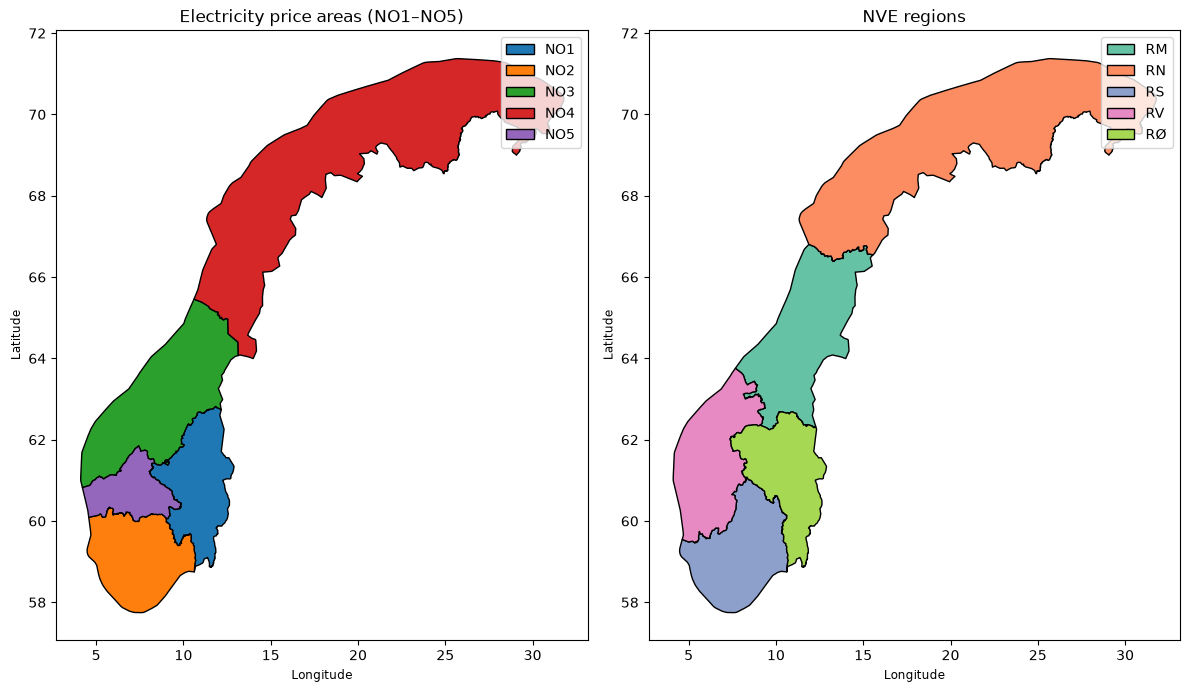

In [2]:
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt

SHAPE_DIR = Path("../shapefiles")

def load_shapefile(folder):
    """Load the single .shp file in a folder and convert it to longitude/latitude (WGS84)."""
    shp_file = next(Path(folder).glob("*.shp"))       # avoids typing names with special letters (å, ø)
    gdf = gpd.read_file(shp_file, encoding="utf-8")   # attribute text (e.g. 'Region Øst') is UTF-8
    return gdf.to_crs(epsg=4326)                      # UTM 33N (metres) -> WGS84 (degrees)

# Electricity price areas NO1-NO5
elspot = load_shapefile(SHAPE_DIR / "elspot")
elspot["area"] = elspot["budomr"].str.replace(" ", "")   # 'NO 1' -> 'NO1'

# NVE regions (precipitation areas)
regions = load_shapefile(SHAPE_DIR / "regions")

display(elspot[["area", "geometry"]])
display(regions[["REGION", "REGIONNAVN", "geometry"]])

# Quick visual check of both maps
fig, axes = plt.subplots(1, 2, figsize=(12, 7))
elspot.plot(column="area", ax=axes[0], legend=True, edgecolor="black", cmap="tab10")
axes[0].set_title("Electricity price areas (NO1–NO5)")
regions.plot(column="REGION", ax=axes[1], legend=True, edgecolor="black", cmap="Set2")
axes[1].set_title("NVE regions")
for ax in axes:
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
plt.tight_layout()
plt.show()

### Regions and random locations

The reservoir statistics use five electricity price areas (**NO1–NO5**) and four watercourse
areas (**VASS1–VASS4**). The electricity areas match the *Budområder* shapefile directly.
The VASS areas are built from the NVE regions according to the official NVE descriptions:

| VASS area | NVE regions |
|---|---|
| VASS1 (South-East) | RØ + RS |
| VASS2 (West) | RV |
| VASS3 (Central Norway) | RM |
| VASS4 (Northern Norway) | RN |

1000 random locations are drawn uniformly inside each of the 9 regions. Sampling is done in the
projected UTM 33N system (metres), so that every square kilometre has the same probability;
the points are then converted back to longitude/latitude. A fixed random seed makes the
selection reproducible, and the locations are saved so that the Streamlit app can reuse them.

region_id
NO1      1000
NO2      1000
NO3      1000
NO4      1000
NO5      1000
VASS1    1000
VASS2    1000
VASS3    1000
VASS4    1000


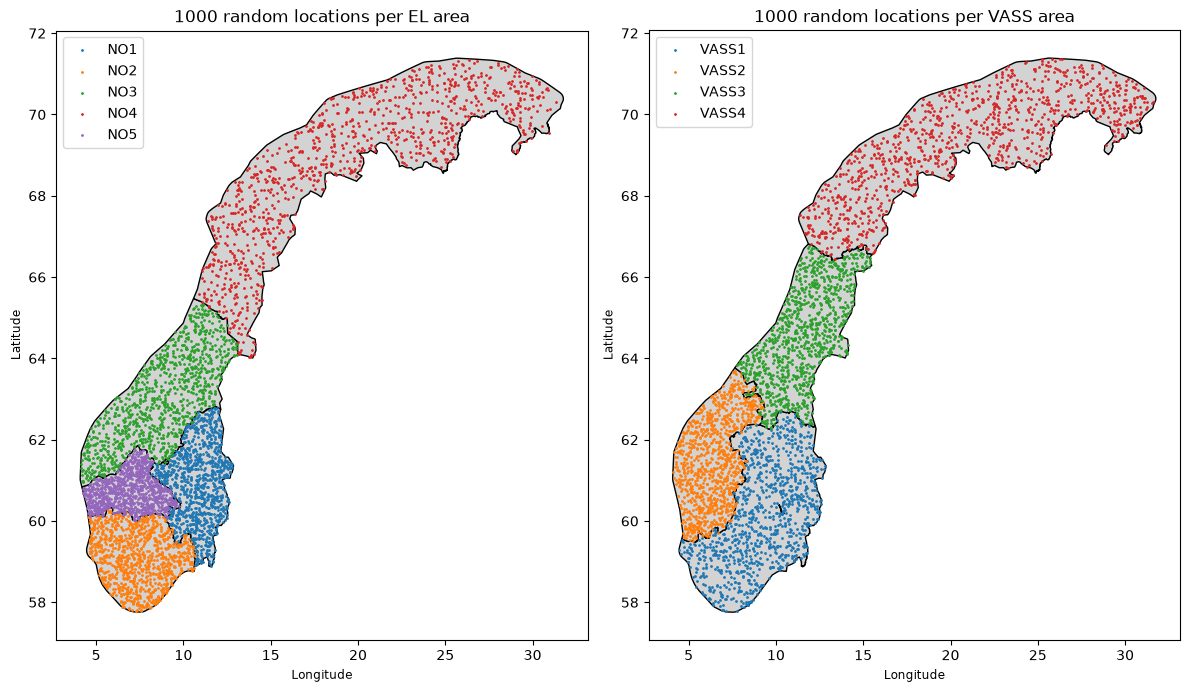

In [3]:
import numpy as np
from shapely import contains_xy

N_LOCATIONS = 1000   # random locations per region
SEED = 42            # fixed seed -> the same locations every time the notebook runs

# 1. VASS areas from the reservoir statistics, built by merging NVE regions
VASS_TO_NVE = {
    "VASS1": ["RØ", "RS"],   # South-East (East = RS + RØ, as noted in the assignment)
    "VASS2": ["RV"],         # West
    "VASS3": ["RM"],         # Central Norway
    "VASS4": ["RN"],         # Northern Norway
}

region_rows = [
    {"region_id": row.area, "region_type": "EL", "geometry": row.geometry}
    for row in elspot.itertuples()
]
for vass_id, nve_codes in VASS_TO_NVE.items():
    merged = regions[regions["REGION"].isin(nve_codes)].union_all()   # merge the polygons
    region_rows.append({"region_id": vass_id, "region_type": "VASS", "geometry": merged})

all_regions = gpd.GeoDataFrame(region_rows, crs="EPSG:4326")


# 2. Random sampling inside a polygon
def sample_points(geometry, n=N_LOCATIONS, seed=SEED):
    """Draw n uniformly distributed random points inside a polygon (given in WGS84).

    Sampling is done in UTM 33N (metres) so that equal areas have equal probability,
    using rejection sampling: random points in the bounding box are kept only if
    they fall inside the polygon.
    """
    polygon = gpd.GeoSeries([geometry], crs="EPSG:4326").to_crs(epsg=25833).iloc[0]
    rng = np.random.default_rng(seed)
    min_x, min_y, max_x, max_y = polygon.bounds

    xs, ys = [], []
    while len(xs) < n:
        cand_x = rng.uniform(min_x, max_x, 5000)
        cand_y = rng.uniform(min_y, max_y, 5000)
        inside = contains_xy(polygon, cand_x, cand_y)   # vectorised point-in-polygon test
        xs.extend(cand_x[inside])
        ys.extend(cand_y[inside])

    points = gpd.GeoSeries(gpd.points_from_xy(xs[:n], ys[:n]), crs="EPSG:25833").to_crs(epsg=4326)
    return pd.DataFrame({"longitude": points.x.round(4), "latitude": points.y.round(4)})


# 3. Sample 1000 locations in every region (a different seed per region)
location_frames = []
for i, row in enumerate(all_regions.itertuples()):
    pts = sample_points(row.geometry, seed=SEED + i)
    pts.insert(0, "region_id", row.region_id)
    pts.insert(1, "region_type", row.region_type)
    location_frames.append(pts)

locations = pd.concat(location_frames, ignore_index=True)
print(locations.groupby("region_id").size().to_string())

# 4. Save the locations for reuse in the Streamlit app (GeoJSON, no CSV)
locations_gdf = gpd.GeoDataFrame(
    locations, geometry=gpd.points_from_xy(locations.longitude, locations.latitude), crs="EPSG:4326"
)
locations_gdf.to_file(SHAPE_DIR / "locations.geojson", driver="GeoJSON")

# 5. Visual check: regions and sampled locations
fig, axes = plt.subplots(1, 2, figsize=(12, 7))
for ax, region_type in zip(axes, ["EL", "VASS"]):
    subset = all_regions[all_regions.region_type == region_type]
    subset.plot(ax=ax, color="lightgrey", edgecolor="black")
    pts = locations_gdf[locations_gdf.region_type == region_type]
    pts.plot(ax=ax, column="region_id", markersize=1, legend=True, cmap="tab10")
    ax.set_title(f"{N_LOCATIONS} random locations per {region_type} area")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
plt.tight_layout()
plt.show()


### Weather data from Open-Meteo (ERA5)

Hourly ERA5 reanalysis data is retrieved from the Open-Meteo Historical Weather API with
`download_weather(region_id, start_date, end_date)`. The function looks up the random locations
of the region, downloads precipitation, temperature and three other variables relevant for
hydropower (rain, snowfall and wind speed), and returns the **regional hourly average**.

**API limits.** The free Open-Meteo API allows 10,000 weighted calls per day (600 per minute),
where a request weighs `locations × days/14 × variables/10`. One year for all 1000 locations
of a region would weigh about 13,000, more than a full day's quota. The function therefore uses
a random subset of the region's locations (default 50, a parameter), downloads them in small
batches with a pause in between, and caches the result locally so it is only downloaded once.

In [4]:
import time
import openmeteo_requests
import requests_cache
from retry_requests import retry

ARCHIVE_URL = "https://archive-api.open-meteo.com/v1/archive"
WEATHER_VARIABLES = ["temperature_2m", "precipitation", "rain", "snowfall", "wind_speed_10m"]
WEATHER_CACHE_DIR = Path("../data/weather")   # inside data/, which is excluded from Git

# Open-Meteo client as generated on open-meteo.com: HTTP cache + automatic retries
cache_session = requests_cache.CachedSession("../data/openmeteo_http_cache", expire_after=-1)
retry_session = retry(cache_session, retries=5, backoff_factor=0.5)
om_client = openmeteo_requests.Client(session=retry_session)


def download_weather(region_id, start_date, end_date, n_locations=50,
                     variables=WEATHER_VARIABLES, batch_size=10, pause_seconds=15,
                     seed=SEED, force_refresh=False):
    """Download hourly ERA5 weather data for a region and return the regional average.

    region_id     : 'NO1'...'NO5' or 'VASS1'...'VASS4'
    start_date    : first day, 'YYYY-MM-DD'
    end_date      : last day, 'YYYY-MM-DD'
    n_locations   : number of the region's random locations to use (API limits, see above)
    batch_size    : locations per API request
    pause_seconds : pause between requests, to respect the per-minute limit
    """
    # Reuse the local copy if this region/period was already downloaded
    cache_file = WEATHER_CACHE_DIR / f"{region_id}_{start_date}_{end_date}_{n_locations}.pkl"
    if cache_file.exists() and not force_refresh:
        return pd.read_pickle(cache_file)

    # Look up the region's locations and pick a reproducible random subset
    region_locations = locations[locations.region_id == region_id]
    if region_locations.empty:
        raise ValueError(f"Unknown region: {region_id}")
    chosen = region_locations.sample(n=min(n_locations, len(region_locations)), random_state=seed)

    frames = []
    for start in range(0, len(chosen), batch_size):
        batch = chosen.iloc[start:start + batch_size]
        params = {
            "latitude": batch.latitude.tolist(),     # several locations in one request
            "longitude": batch.longitude.tolist(),
            "start_date": start_date,
            "end_date": end_date,
            "hourly": variables,
            "models": "era5",
            "timezone": "UTC",
        }
        responses = om_client.weather_api(ARCHIVE_URL, params=params)

        # One response per location: build an hourly DataFrame for each
        for response in responses:
            hourly = response.Hourly()
            times = pd.date_range(
                start=pd.to_datetime(hourly.Time(), unit="s", utc=True),
                end=pd.to_datetime(hourly.TimeEnd(), unit="s", utc=True),
                freq=pd.Timedelta(seconds=hourly.Interval()),
                inclusive="left",
            )
            values = {var: hourly.Variables(i).ValuesAsNumpy() for i, var in enumerate(variables)}
            frames.append(pd.DataFrame(values, index=times))

        print(f"  {region_id}: {min(start + batch_size, len(chosen))}/{len(chosen)} locations")
        if start + batch_size < len(chosen):
            time.sleep(pause_seconds)   # stay below the per-minute API limit

    # Regional average over all locations, in Norwegian local time
    regional = pd.concat(frames).groupby(level=0).mean()
    regional.index = regional.index.tz_convert("Europe/Oslo")
    regional.index.name = "time"

    WEATHER_CACHE_DIR.mkdir(parents=True, exist_ok=True)
    regional.to_pickle(cache_file)
    return regional


# Apply the function: price area NO3 for the year 2024
weather_no3 = download_weather("NO3", "2024-01-01", "2024-12-31")
print(f"\n{len(weather_no3):,} hourly values")
display(weather_no3.head())
display(weather_no3.describe().round(2))


8,784 hourly values


,temperature_2m,precipitation,rain,snowfall,wind_speed_10m
time,,,,,
2024-01-01 01:00:00+01:00,-3.05104,0.002,0.0,0.0014,26.378454
2024-01-01 02:00:00+01:00,-3.18004,0.002,0.0,0.0014,26.668518
2024-01-01 03:00:00+01:00,-3.13204,0.002,0.0,0.0014,27.070524
2024-01-01 04:00:00+01:00,-3.14504,0.002,0.0,0.0014,27.206196
2024-01-01 05:00:00+01:00,-3.10104,0.002,0.0,0.0014,27.351252


,temperature_2m,precipitation,rain,snowfall,wind_speed_10m
count,8784.00,8784.00,8784.00,8784.00,8784.00
mean,6.34,0.21,0.18,0.02,14.95
std,6.53,0.28,0.26,0.05,6.10
min,-10.49,0.00,0.00,0.00,3.63
25%,1.90,0.01,0.01,0.00,10.45
50%,6.02,0.10,0.08,0.00,13.72
75%,11.53,0.29,0.25,0.01,18.44
max,22.88,2.58,2.36,0.69,48.39


## Outliers: Statistical Process Control (SPC) on precipitation

The average hourly precipitation in NO3 (2024) is plotted together with SPC limits:

1. A **Discrete Cosine Transform (DCT)** splits the series into slow and fast components.
   Removing the slow ones (periods longer than `cutoff_days`) is a high-pass filter that gives the
   **seasonally adjusted variations (SATV)**; the slow part is the seasonal level.
2. **Robust statistics** of the SATV are estimated on the whole year: the median as centre and
   1.4826 × MAD (median absolute deviation) as a standard deviation that is not distorted by
   the extreme values we want to detect.
3. The **SPC limits** are the seasonal level + median ± `n_std` robust standard deviations.
   Hours outside the limits are outliers and are shown in a contrasting colour.
   The SATV itself is not plotted; it is only used to compute the limits.

Note: the assignment text applies this method to precipitation (as followed here), although the
term SATV refers to temperature. The variable is a parameter, so the function works for both.

In [5]:
import numpy as np
from scipy.fft import dct, idct


def spc_outliers(weather, variable="precipitation", cutoff_days=30, n_std=3.0, region_label=""):
    """Detect outliers with Statistical Process Control on DCT high-pass filtered data.

    weather      : DataFrame with an hourly DatetimeIndex (e.g. from download_weather)
    variable     : column to analyse (default 'precipitation')
    cutoff_days  : variations slower than this period are treated as seasonal and removed
    n_std        : number of robust standard deviations for the SPC limits
    Returns (figure, summary dict, DataFrame of outliers).
    """
    series = weather[variable].astype(float)
    x = series.to_numpy()
    n = len(x)
    step_hours = (series.index[1] - series.index[0]).total_seconds() / 3600

    # 1. DCT high-pass filter. DCT-II coefficient k has a period of about 2·n·step / k,
    #    so coefficients below k_cut describe variations slower than cutoff_days.
    coeffs = dct(x, type=2, norm="ortho")
    k_cut = int(np.ceil(2 * n * step_hours / (cutoff_days * 24)))
    low_coeffs = coeffs.copy()
    low_coeffs[k_cut:] = 0
    seasonal = idct(low_coeffs, type=2, norm="ortho")   # slow, seasonal level
    satv = x - seasonal                                  # seasonally adjusted variations

    # 2. Robust statistics of the SATV over the whole year
    centre = np.median(satv)
    sigma = 1.4826 * np.median(np.abs(satv - centre))    # MAD scaled to a standard deviation
    if sigma == 0:                                       # safety net for constant data
        sigma = satv.std()

    # 3. SPC limits on the original scale and outlier detection
    lower = seasonal + centre - n_std * sigma
    upper = seasonal + centre + n_std * sigma
    is_outlier = (x < lower) | (x > upper)

    outliers = pd.DataFrame({
        variable: x[is_outlier],
        "lower_limit": lower[is_outlier],
        "upper_limit": upper[is_outlier],
        "type": np.where(x[is_outlier] > upper[is_outlier], "high", "low"),
    }, index=series.index[is_outlier])

    # 4. Plot: data, SPC limit curves and outliers in a contrasting colour (SATV not plotted)
    fig, ax = plt.subplots(figsize=(13, 5))
    ax.plot(series.index, x, color="steelblue", linewidth=0.6, label=f"Hourly {variable}")
    ax.plot(series.index, upper, color="orange", linewidth=1.2, linestyle="--", label="SPC limits")
    ax.plot(series.index, lower, color="orange", linewidth=1.2, linestyle="--")
    ax.scatter(outliers.index, outliers[variable], color="red", s=10, zorder=3,
               label=f"Outliers ({is_outlier.sum()})")
    unit = "mm" if variable in ("precipitation", "rain", "snowfall") else "°C"
    ax.set_title(f"{variable.capitalize()} with SPC limits {region_label} "
                 f"(cut-off {cutoff_days} days, ±{n_std} robust SD)")
    ax.set_xlabel("Time")
    ax.set_ylabel(f"{variable.capitalize()} [{unit}]")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper right")
    fig.tight_layout()
    plt.close(fig)   # the caller decides when to show the figure

    summary = {
        "variable": variable,
        "cutoff_days": cutoff_days,
        "n_std": n_std,
        "dct_coefficients_removed": k_cut,
        "robust_sd": round(float(sigma), 4),
        "n_values": n,
        "n_outliers": int(is_outlier.sum()),
        "outlier_share_%": round(100 * is_outlier.mean(), 2),
        "n_high": int((outliers["type"] == "high").sum()),
        "n_low": int((outliers["type"] == "low").sum()),
        "max_outlier_value": round(float(outliers[variable].max()), 3) if len(outliers) else None,
    }
    return fig, summary, outliers

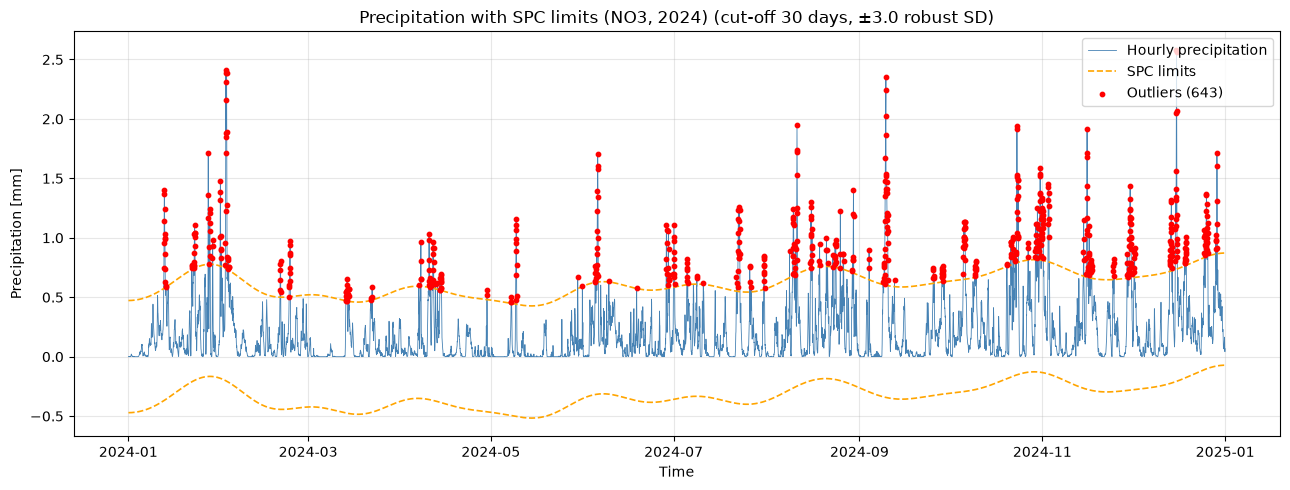

variable                    precipitation
cutoff_days                            30
n_std                                 3.0
dct_coefficients_removed               25
robust_sd                          0.1573
n_values                             8784
n_outliers                            643
outlier_share_%                      7.32
n_high                                643
n_low                                   0
max_outlier_value                   2.582
Name: SPC summary, dtype: object

Largest outliers:


,precipitation,lower_limit,upper_limit,type
time,,,,
2024-12-15 18:00:00+01:00,2.582,-0.208,0.736,high
2024-12-15 19:00:00+01:00,2.560,-0.207,0.736,high
2024-02-02 18:00:00+01:00,2.412,-0.205,0.738,high
2024-02-02 19:00:00+01:00,2.388,-0.206,0.738,high
2024-02-02 13:00:00+01:00,2.388,-0.203,0.741,high
2024-09-09 20:00:00+02:00,2.356,-0.343,0.601,high
2024-02-02 14:00:00+01:00,2.314,-0.203,0.740,high
2024-09-09 19:00:00+02:00,2.246,-0.343,0.601,high
2024-02-02 17:00:00+01:00,2.162,-0.205,0.739,high


cutoff_days=30, n_std=3: 643 outliers (7.32%)
cutoff_days=30, n_std=4: 351 outliers (4.0%)
cutoff_days= 7, n_std=3: 561 outliers (6.39%)


In [6]:
# Test 1: default parameters on NO3, 2024
fig, summary, outliers = spc_outliers(weather_no3, region_label="(NO3, 2024)")
display(fig)
display(pd.Series(summary, name="SPC summary"))
print("Largest outliers:")
display(outliers.sort_values("precipitation", ascending=False).head(10).round(3))

# Test 2: the parameters change the result as expected
# (stricter limits -> fewer outliers; a shorter cut-off removes more of the slow variation)
for cutoff, k in [(30, 3), (30, 4), (7, 3)]:
    _, s, _ = spc_outliers(weather_no3, cutoff_days=cutoff, n_std=k)
    print(f"cutoff_days={cutoff:>2}, n_std={k}: {s['n_outliers']} outliers ({s['outlier_share_%']}%)")

#### Interpretation

With the default parameters (cut-off 30 days, ±3 robust SD), 643 of 8,784 hours (7.3%) are
flagged as outliers, all of them above the upper limit: they correspond to hours of intense
precipitation. There are no low outliers, because precipitation cannot be negative; for the same
reason the lower SPC limit has no physical meaning here, even though it follows from the
symmetric limits. The share of outliers is much higher than the ~0.3% expected for normally
distributed data, because hourly precipitation is strongly skewed (mostly near zero, with rare
intense peaks), which keeps the robust standard deviation small. The limits follow the seasonal
level, which is higher in autumn and winter when precipitation is more frequent.

## Anomalies: Local Outlier Factor (LOF) on temperature

The average hourly temperature in NO3 (2024) is plotted and anomalies are marked with the
**Local Outlier Factor** method. LOF compares the local density of each point with the density
of its nearest neighbours: points lying in much sparser regions than their neighbours get a high
LOF score and are flagged as anomalies. Each hour is described by its temperature and its time,
so that a value is compared with the temperatures around the same period rather than with the
whole year. The expected proportion of anomalies (`contamination`) is a parameter with a default
of 1%.

In [7]:
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler


def lof_anomalies(weather, variable="temperature_2m", contamination=0.01, n_neighbors=50,
                  region_label=""):
    """Detect anomalies with the Local Outlier Factor method.

    weather       : DataFrame with an hourly DatetimeIndex (e.g. from download_weather)
    variable      : column to analyse (default 'temperature_2m')
    contamination : expected proportion of anomalies (default 1%)
    n_neighbors   : number of neighbours used to estimate the local density
    Returns (figure, summary dict, DataFrame of anomalies).
    """
    series = weather[variable].astype(float)

    # Features: time (in hours from the start) and value. Both are standardised so that
    # they have the same weight in the distance between points.
    hours = (series.index - series.index[0]).total_seconds().to_numpy() / 3600
    features = StandardScaler().fit_transform(np.column_stack([hours, series.to_numpy()]))

    lof = LocalOutlierFactor(n_neighbors=n_neighbors, contamination=contamination)
    labels = lof.fit_predict(features)          # -1 = anomaly, 1 = normal
    scores = -lof.negative_outlier_factor_      # LOF score: higher = more anomalous
    is_anomaly = labels == -1

    anomalies = pd.DataFrame({
        variable: series[is_anomaly],
        "lof_score": scores[is_anomaly].round(3),
    })

    # Plot: temperature with anomalies in a contrasting colour
    fig, ax = plt.subplots(figsize=(13, 5))
    ax.plot(series.index, series, color="steelblue", linewidth=0.6, label=f"Hourly {variable}")
    ax.scatter(anomalies.index, anomalies[variable], color="red", s=12, zorder=3,
               label=f"Anomalies ({is_anomaly.sum()})")
    ax.set_title(f"Temperature with LOF anomalies {region_label} "
                 f"(contamination {contamination:.1%}, {n_neighbors} neighbours)")
    ax.set_xlabel("Time")
    ax.set_ylabel("Temperature [°C]")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper right")
    fig.tight_layout()
    plt.close(fig)

    summary = {
        "variable": variable,
        "contamination": contamination,
        "n_neighbors": n_neighbors,
        "n_values": len(series),
        "n_anomalies": int(is_anomaly.sum()),
        "anomaly_share_%": round(100 * is_anomaly.mean(), 2),
        "min_anomaly_value": round(float(anomalies[variable].min()), 2) if len(anomalies) else None,
        "max_anomaly_value": round(float(anomalies[variable].max()), 2) if len(anomalies) else None,
        "max_lof_score": round(float(scores.max()), 3),
    }
    return fig, summary, anomalies
    

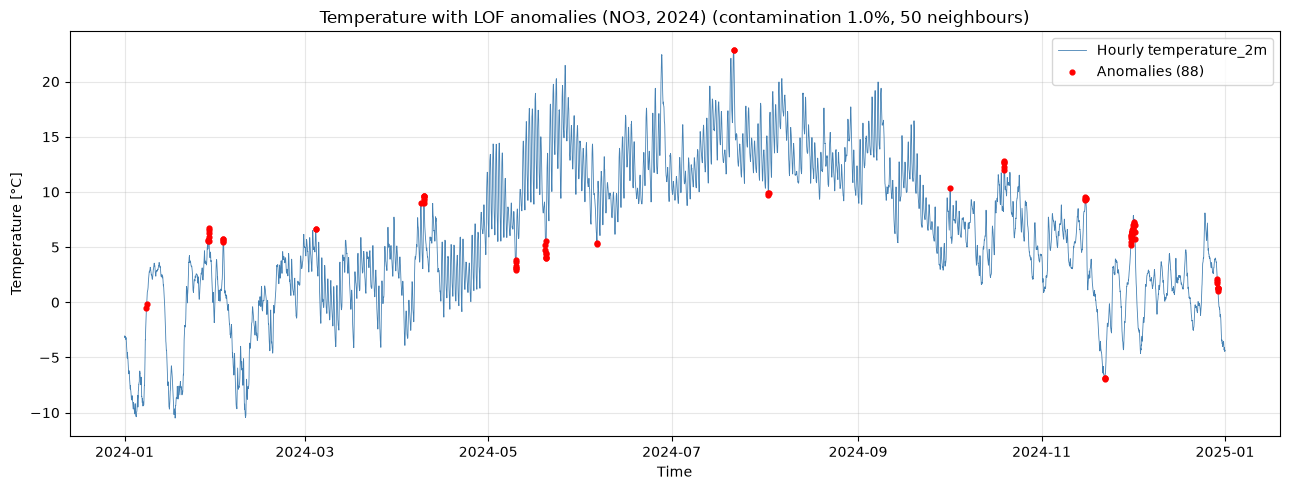

variable             temperature_2m
contamination                  0.01
n_neighbors                      50
n_values                       8784
n_anomalies                      88
anomaly_share_%                 1.0
min_anomaly_value             -6.92
max_anomaly_value             22.88
max_lof_score                 2.218
Name: LOF summary, dtype: object

Most anomalous hours:


,temperature_2m,lof_score
time,,
2024-10-19 16:00:00+02:00,12.679959,2.218
2024-10-19 15:00:00+02:00,12.815960,2.215
2024-10-19 14:00:00+02:00,12.579960,2.192
2024-10-19 17:00:00+02:00,12.269959,1.906
2024-05-20 05:00:00+02:00,4.012960,1.897
2024-05-20 04:00:00+02:00,4.004960,1.895
2024-01-29 00:00:00+01:00,6.731960,1.845
2024-12-02 03:00:00+01:00,5.746960,1.810
2024-05-20 03:00:00+02:00,4.147960,1.802


contamination=0.5%: 44 anomalies (0.5%)
contamination=1.0%: 88 anomalies (1.0%)
contamination=2.0%: 176 anomalies (2.0%)


In [8]:
# Test 1: default parameters (1% anomalies) on NO3, 2024
fig, summary, anomalies = lof_anomalies(weather_no3, region_label="(NO3, 2024)")
display(fig)
display(pd.Series(summary, name="LOF summary"))
print("Most anomalous hours:")
display(anomalies.sort_values("lof_score", ascending=False).head(10))

# Test 2: the share of anomalies follows the contamination parameter
for share in [0.005, 0.01, 0.02]:
    _, s, _ = lof_anomalies(weather_no3, contamination=share)
    print(f"contamination={share:.1%}: {s['n_anomalies']} anomalies ({s['anomaly_share_%']}%)")

#### Interpretation

With the default contamination of 1%, 88 of 8,784 hours are flagged as anomalies. Since each
hour is described by both its time and its temperature, LOF marks values that are unusual
compared with the temperatures around the same period, not just the coldest or warmest values
of the year: for example short warm spells in winter, sudden drops, or isolated peaks. This is
the main difference from the SPC approach, which uses fixed limits around a seasonal level.
The number of anomalies follows the `contamination` parameter directly.

## Seasonal-Trend decomposition with LOESS (STL)

The weekly filling rate of the reservoirs (NVE Magasinstatistikk API) is decomposed with STL into
a **trend** (long-term level), a **seasonal** component (the yearly cycle: emptying in winter,
filling in spring and summer) and a **residual** (what remains, e.g. unusually dry or wet years).
The period is 52 weeks. The parameters are:

- `seasonal` (default 13): length of the seasonal smoother, in weeks (odd number);
- `trend` (default 105): length of the trend smoother, about two years (odd, longer than the period);
- `robust` (default True): robust fitting that reduces the influence of outliers.

The area is selected with `area_type` and `area_number`, as in the reservoir selector of the app.

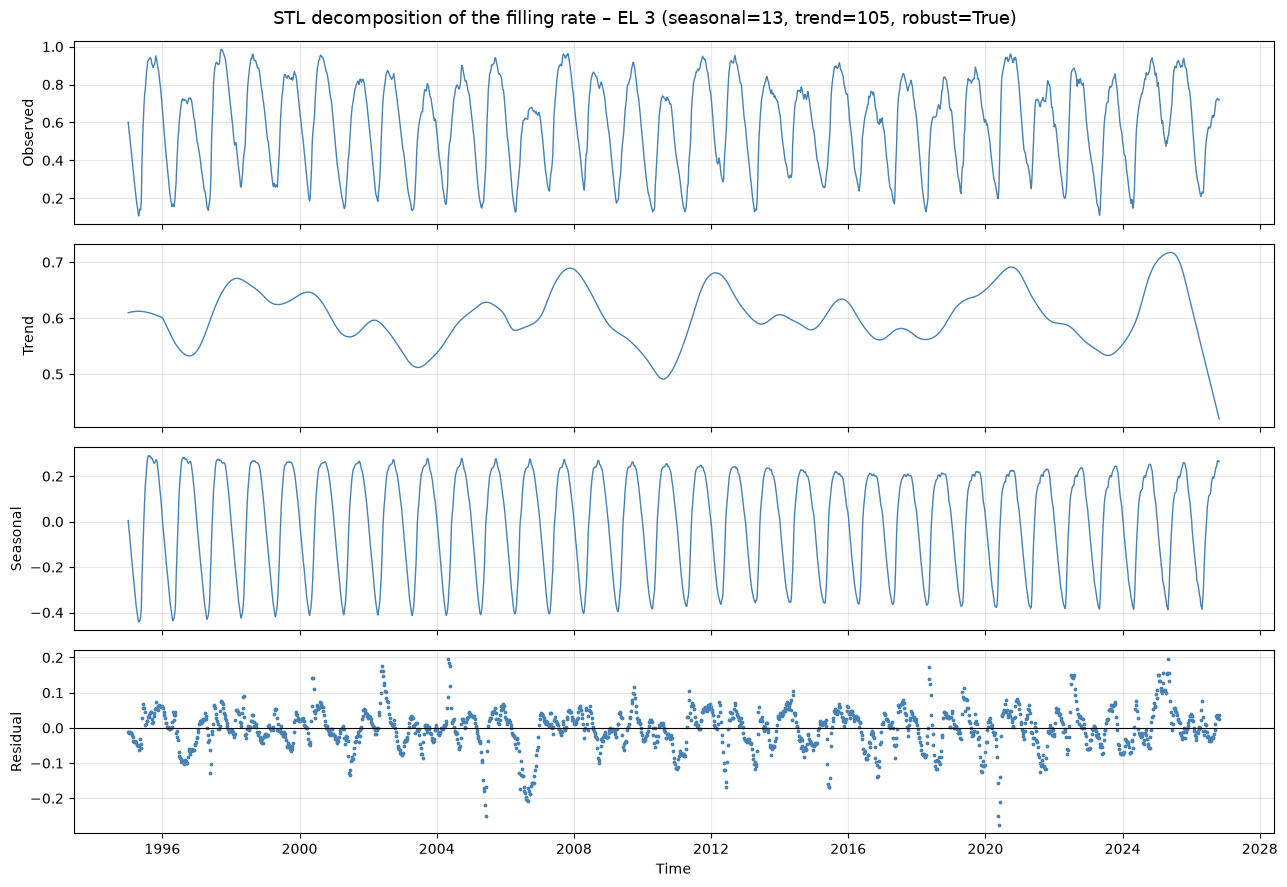

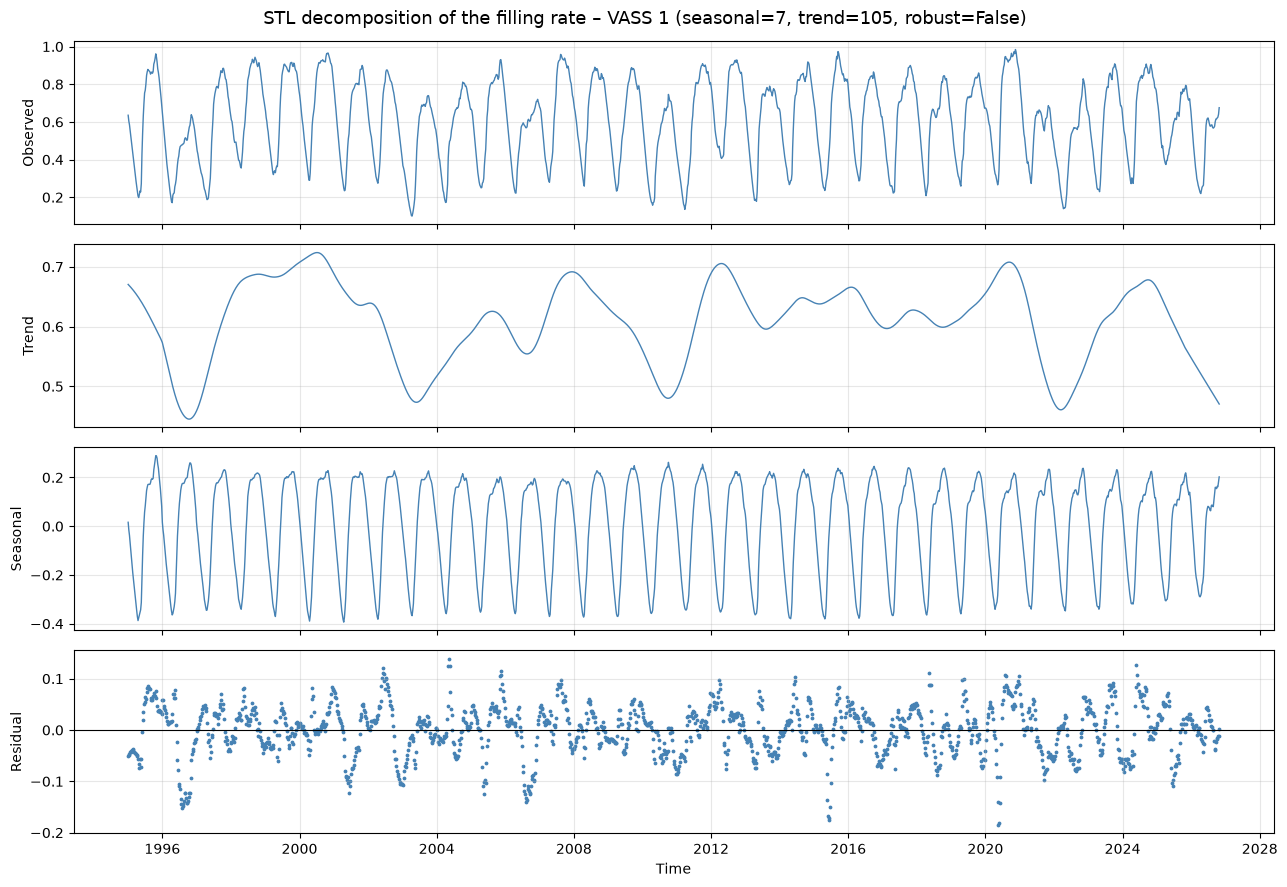

In [9]:
from statsmodels.tsa.seasonal import STL

NVE_URL = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"


def load_reservoirs():
    """Download the weekly reservoir statistics from the NVE Magasinstatistikk API."""
    response = requests.get(NVE_URL, timeout=60)
    response.raise_for_status()
    res = pd.DataFrame(response.json())
    # ISO year + ISO week -> date (Monday of the week)
    res["Date"] = pd.to_datetime(
        res["iso_aar"].astype(str) + "-" + res["iso_uke"].astype(str) + "-1", format="%G-%V-%u"
    )
    return res.rename(columns={"omrType": "Area_Type", "omrnr": "Area_Number",
                               "fyllingsgrad": "Fill_Rate"})


def reservoir_series(reservoirs, area_type="EL", area_number=3):
    """Weekly filling rate of one area as a regular time series (no gaps)."""
    s = (reservoirs[(reservoirs.Area_Type == area_type) & (reservoirs.Area_Number == area_number)]
         .set_index("Date")["Fill_Rate"].sort_index())
    s = s[~s.index.duplicated()]
    return s.asfreq("W-MON").interpolate()   # fill any missing week by linear interpolation


def stl_decomposition(reservoirs, area_type="EL", area_number=3,
                      seasonal=13, trend=105, robust=True):
    """STL decomposition of the weekly filling rate. Returns the figure."""
    series = reservoir_series(reservoirs, area_type, area_number)
    result = STL(series, period=52, seasonal=seasonal, trend=trend, robust=robust).fit()

    parts = [("Observed", result.observed), ("Trend", result.trend),
             ("Seasonal", result.seasonal), ("Residual", result.resid)]
    fig, axes = plt.subplots(4, 1, figsize=(13, 9), sharex=True)
    for ax, (name, values) in zip(axes, parts):
        if name == "Residual":
            ax.scatter(values.index, values, s=3, color="steelblue")
            ax.axhline(0, color="black", linewidth=0.8)
        else:
            ax.plot(values.index, values, color="steelblue", linewidth=1)
        ax.set_ylabel(name)
        ax.grid(alpha=0.3)
    axes[-1].set_xlabel("Time")
    fig.suptitle(f"STL decomposition of the filling rate – {area_type} {area_number} "
                 f"(seasonal={seasonal}, trend={trend}, robust={robust})", fontsize=13)
    fig.tight_layout()
    plt.close(fig)
    return fig


# Test: download the reservoir data once and run the decomposition
reservoirs = load_reservoirs()
display(stl_decomposition(reservoirs))                                  # defaults: EL 3 (NO3)
display(stl_decomposition(reservoirs, area_type="VASS", area_number=1,  # other area and parameters
                          seasonal=7, robust=False))

#### Interpretation

The **seasonal** component shows a very regular yearly cycle with an amplitude of about ±0.3
in filling rate: reservoirs fill up with snowmelt in spring and summer and are emptied during
winter. The **trend** varies between roughly 0.45 and 0.72 and reveals dry periods (e.g. around
1996, 2003, 2010 and 2022) and wetter ones. The **residuals** are mostly small and centred on
zero; the larger negative residuals mark weeks that are lower than expected from trend and
season. Changing the parameters (e.g. a shorter seasonal smoother and non-robust fitting in the
second test) gives a seasonal component that adapts more from year to year.

## Spectrogram

The spectrogram shows which frequencies are present in the weekly filling rate and how they
change over time. The series is split into overlapping windows and the power spectrum of each
window is computed. Frequencies are given in **cycles per year** (52 samples per year), so the
yearly filling cycle appears at 1 cycle/year. The parameters are:

- `window_length` (default 104 weeks = 2 years): long enough to contain the yearly cycle twice
  and give a good frequency resolution;
- `window_overlap` (default 78 weeks = 75% of the window): a smooth evolution over time.

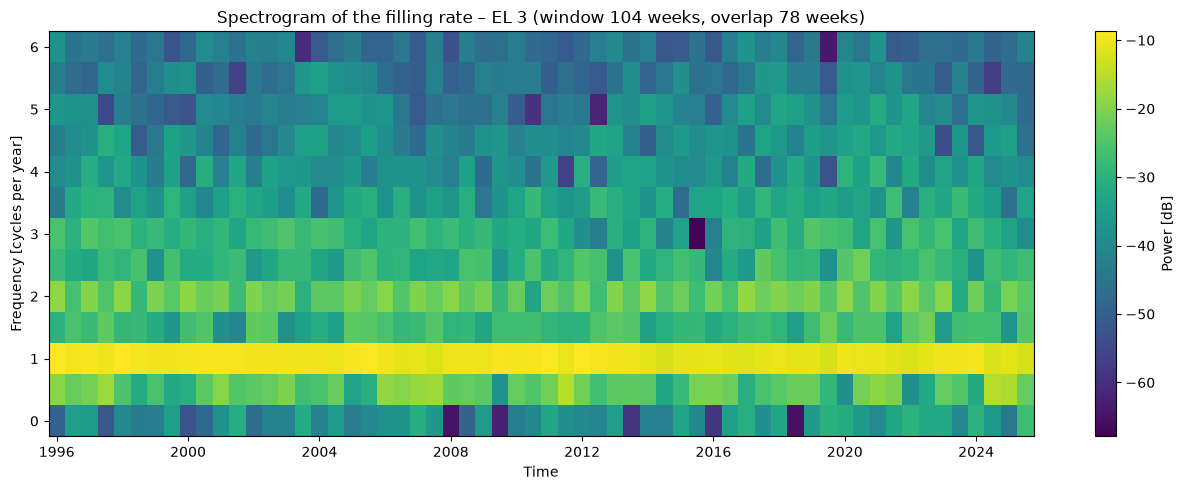

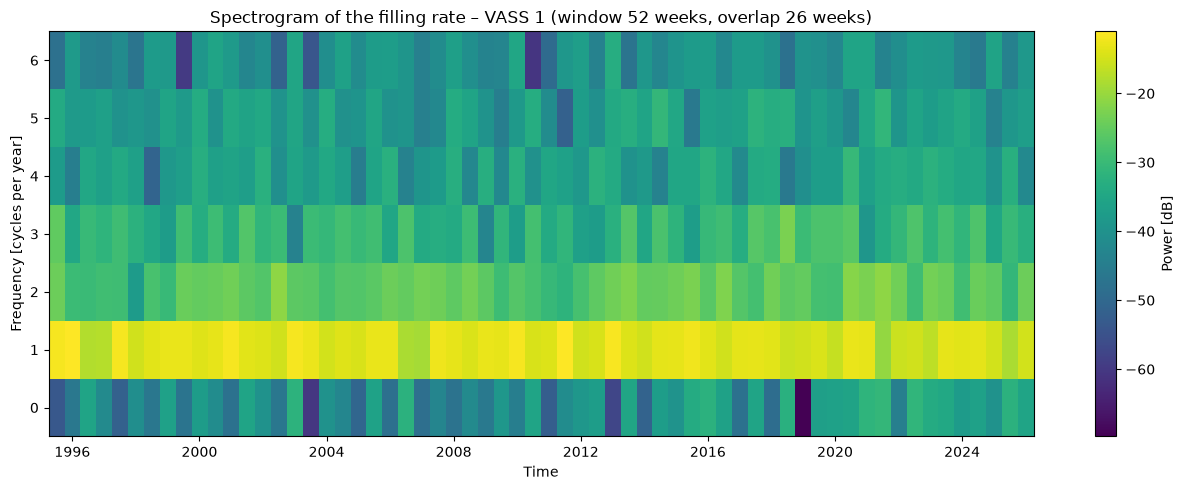

In [10]:
from scipy.signal import spectrogram


def reservoir_spectrogram(reservoirs, area_type="EL", area_number=3,
                          window_length=104, window_overlap=78, max_frequency=6):
    """Spectrogram of the weekly filling rate. Returns the figure.

    window_length  : window length in weeks
    window_overlap : overlap between consecutive windows in weeks (must be < window_length)
    max_frequency  : highest frequency shown, in cycles per year
    """
    if window_overlap >= window_length:
        raise ValueError("window_overlap must be smaller than window_length")

    series = reservoir_series(reservoirs, area_type, area_number)
    freqs, times, power = spectrogram(
        series.to_numpy(),
        fs=52,                    # 52 weekly samples per year -> frequencies in cycles/year
        nperseg=window_length,
        noverlap=window_overlap,
        detrend="constant",       # remove the mean of each window
        scaling="density",
    )
    # Window centres (in years from the start) -> calendar dates
    dates = series.index[0] + pd.to_timedelta(times * 365.25, unit="D")
    keep = freqs <= max_frequency

    fig, ax = plt.subplots(figsize=(13, 5))
    mesh = ax.pcolormesh(dates, freqs[keep], 10 * np.log10(power[keep] + 1e-12),
                         shading="nearest", cmap="viridis")
    fig.colorbar(mesh, ax=ax, label="Power [dB]")
    ax.set_title(f"Spectrogram of the filling rate – {area_type} {area_number} "
                 f"(window {window_length} weeks, overlap {window_overlap} weeks)")
    ax.set_xlabel("Time")
    ax.set_ylabel("Frequency [cycles per year]")
    fig.tight_layout()
    plt.close(fig)
    return fig


# Test: default parameters, and a shorter window with less overlap for another area
display(reservoir_spectrogram(reservoirs))
display(reservoir_spectrogram(reservoirs, area_type="VASS", area_number=1,
                              window_length=52, window_overlap=26))

#### Interpretation

The spectrogram shows a strong, continuous band at **1 cycle per year** throughout the whole
period: the yearly filling and emptying cycle dominates the filling rate and is stable over the
years. A weaker band at 2 cycles per year is a harmonic, caused by the cycle not being a pure
sine wave (fast filling in spring, slower emptying in winter). Higher frequencies contain only
low-power noise. With a shorter window (second test) the time resolution improves, but the
frequency resolution becomes coarser: the classic trade-off of the spectrogram.